# Betting Against Beta — Part B: Section 2 (CAPM tests) and Section 3 (default book)

**Data.** CRSP monthly common stocks on NYSE, AMEX and Nasdaq, 1963-01 to 2026-09, and Ken French's `Mkt-RF` and `RF`. We use the supplied **delisting-adjusted returns** (`ret`). Excess returns subtract `RF`; the market is `Mkt-RF`.

**Conventions.** A portfolio formed at month end *t* uses data through *t*, earns the return of *t+1*, and uses market cap at *t*. Members at *t* need a beta, positive market cap, a price, and no delisting code at *t*. A held stock with a missing return in *t+1* earns a total return of zero (excess −RF) and keeps its weight. Betas omit months with a missing return. Means are annualized ×12 and volatilities ×√12; alphas are annualized with plain OLS t-statistics. **Every full-sample exhibit runs from 1966-01 to 2026-09** (the first 60-month betas, at their 36-month minimum, exist at the end of 1965).

The shared functions live in `bab_core.py` in this folder, so Sections 4–6 can reuse them. Section 2 needs the 1.2 deciles, so this notebook recomputes them with `bc.decile_sort`. Part A's Section 1 should produce the same numbers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import bab_core as bc

panel = bc.load_panel()
mkt = panel.mkt
beta60 = bc.rolling_beta(panel.ex, mkt, 60, 36)      # trailing 60 months, at least 36
print(f"{panel.ret.shape[0]} months x {panel.ret.shape[1]:,} permnos, "
      f"{panel.ret.index[0]:%Y-%m} to {panel.ret.index[-1]:%Y-%m}")


def show(df, pct=(), precision=3):
    display(df.style.format({c: "{:.2%}" for c in pct}, precision=precision))

765 months x 26,519 permnos, 1963-01 to 2026-09


## 2. What the Returns Say About the CAPM

Deciles from 1.2: ranked each month end from 1965-12 on the 60-month beta, ten equal-count groups, value-weighted, held one month. Holding months 1966-01 to 2026-09.

In [2]:
dec_ex, dec_pre, dec_n = bc.decile_sort(beta60, panel)


def decile_table(ex, pre):
    m = mkt.reindex(ex.index)
    rows = {}
    for g in ex:
        alpha, beta, t_alpha, _, _, _ = bc.ols(ex[g], m)
        rows[g] = {"mean_excess": 12 * ex[g].mean(), "pre_beta": pre[g].mean(),
                   "post_beta": beta, "alpha": 12 * alpha, "t_alpha": t_alpha}
    return pd.DataFrame(rows).T.rename_axis("decile")


def cross_section(table, premium):
    out = {}
    for x in ["post_beta", "pre_beta"]:
        a, b, t_a, t_b, _, r2 = bc.ols(table["mean_excess"], table[x])
        out[x] = {"intercept": a, "t_intercept": t_a, "slope": b, "t_slope": t_b,
                  "R2": r2, "market_premium": premium}
    return pd.DataFrame(out).T.rename_axis("regressor")


def h_stat(ex):
    # H = T [1 + SR_m^2]^-1 alpha' Sigma^-1 alpha ~ chi2(n); monthly alphas, Sigma = residual covariance (/T)
    m = mkt.reindex(ex.index)
    fits = [bc.ols(ex[g], m) for g in ex]
    alpha = np.array([f[0] for f in fits])
    resid = np.column_stack([f[4] for f in fits])
    T = len(ex)
    sigma = resid.T @ resid / T
    sr = m.mean() / m.std()
    H = T / (1 + sr**2) * alpha @ np.linalg.solve(sigma, alpha)
    return H, stats.chi2.sf(H, len(alpha))


full = decile_table(dec_ex, dec_pre)
premium = 12 * mkt.reindex(dec_ex.index).mean()
print(f"Value-weighted beta deciles, 1966-01 to 2026-09; sample market premium {premium:.2%} a year")
show(full, pct=["mean_excess", "alpha"])

Value-weighted beta deciles, 1966-01 to 2026-09; sample market premium 7.03% a year


,mean_excess,pre_beta,post_beta,alpha,t_alpha
decile,,,,,
1,6.06%,0.225,0.536,2.29%,1.848
2,6.25%,0.492,0.646,1.71%,1.754
3,7.81%,0.680,0.758,2.49%,2.766
4,7.18%,0.837,0.868,1.08%,1.309
5,7.93%,0.991,0.979,1.05%,1.332
6,8.28%,1.144,1.073,0.74%,0.908
7,6.69%,1.314,1.195,-1.71%,-2.061
8,7.25%,1.520,1.299,-1.87%,-1.909
9,8.56%,1.811,1.493,-1.92%,-1.301


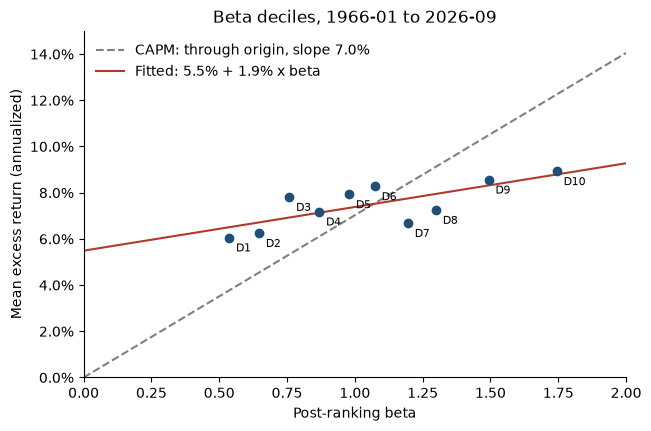

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(full["post_beta"], full["mean_excess"], color="#1f4e79", zorder=3)
for g, r in full.iterrows():
    ax.annotate(f"D{g}", (r["post_beta"], r["mean_excess"]), textcoords="offset points", xytext=(5, -10), fontsize=8)
grid = np.linspace(0, 2, 50)
a, b, *_ = bc.ols(full["mean_excess"], full["post_beta"])
ax.plot(grid, premium * grid, color="grey", ls="--", label=f"CAPM: through origin, slope {premium:.1%}")
ax.plot(grid, a + b * grid, color="#b03a2e", label=f"Fitted: {a:.1%} + {b:.1%} x beta")
ax.set(xlabel="Post-ranking beta", ylabel="Mean excess return (annualized)",
       title="Beta deciles, 1966-01 to 2026-09", xlim=(0, 2), ylim=(0, 0.15))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

### 2.1 Cross-sectional regression

Ten decile mean excess returns regressed on their betas with an intercept, 1966-01 to 2026-09. Intercept, slope and premium are annualized.

In [4]:
show(cross_section(full, premium), pct=["intercept", "slope", "market_premium"])

,intercept,t_intercept,slope,t_slope,R2,market_premium
regressor,,,,,,
post_beta,5.49%,8.127,1.89%,3.134,0.551,7.03%
pre_beta,6.21%,13.837,1.13%,3.261,0.571,7.03%


### 2.2 Joint test on the ten alphas, and sub-periods

In [5]:
periods = {"1966-01 to 2026-09": (None, None),
           "1966-01 to 2013-12": (None, "2013-12"),
           "2014-01 to 2026-09": ("2014-01", None)}

cs_rows, h_rows = [], {}
for name, (start, end) in periods.items():
    ex, pre = dec_ex.loc[start:end], dec_pre.loc[start:end]
    prem = 12 * mkt.reindex(ex.index).mean()
    cs_rows.append(cross_section(decile_table(ex, pre), prem).assign(period=name))
    H, p = h_stat(ex)
    h_rows[name] = {"H": H, "p_value": p, "months": len(ex)}

show(pd.concat(cs_rows).reset_index().set_index(["period", "regressor"]),
     pct=["intercept", "slope", "market_premium"])
show(pd.DataFrame(h_rows).T.astype({"months": int}).rename_axis("period"))

,H,p_value,months
period,,,
1966-01 to 2026-09,14.941,0.134,729
1966-01 to 2013-12,14.520,0.151,576
2014-01 to 2026-09,5.344,0.867,153


### 2.3 Shrinking the sort beta

Regress the post-ranking decile betas on the pre-ranking decile betas (full sample) to get *w*. Then re-form the deciles on $\beta^* = w\hat\beta + (1-w)$.

In [6]:
w_hat = bc.ols(full["post_beta"], full["pre_beta"])[1]
star_ex, star_pre, _ = bc.decile_sort(bc.shrink(beta60, w_hat), panel)
star = decile_table(star_ex, star_pre)

print(f"slope of post- on pre-ranking decile betas: w = {w_hat:.3f}")
print(f"largest difference in decile returns after re-forming: {(star_ex - dec_ex).abs().max().max():.1e}")

compare = pd.concat({"raw 60m beta": cross_section(full, premium),
                     "shrunk beta*": cross_section(star, premium)}, names=["sort"])
show(compare, pct=["intercept", "slope", "market_premium"])
show(pd.DataFrame({"pre_beta raw": full["pre_beta"], "pre_beta shrunk": star["pre_beta"],
                   "post_beta raw": full["post_beta"], "post_beta shrunk": star["post_beta"]}))
print(f"H raw = {h_stat(dec_ex)[0]:.2f}, H shrunk = {h_stat(star_ex)[0]:.2f}")

slope of post- on pre-ranking decile betas: w = 0.583
largest difference in decile returns after re-forming: 0.0e+00


,pre_beta raw,pre_beta shrunk,post_beta raw,post_beta shrunk
decile,,,,
1,0.225,0.549,0.536,0.536
2,0.492,0.704,0.646,0.646
3,0.680,0.813,0.758,0.758
4,0.837,0.905,0.868,0.868
5,0.991,0.994,0.979,0.979
6,1.144,1.084,1.073,1.073
7,1.314,1.183,1.195,1.195
8,1.520,1.303,1.299,1.299
9,1.811,1.473,1.493,1.493


H raw = 14.94, H shrunk = 14.94


**What changes and what does not.** $\beta^*$ is an increasing linear function of $\hat\beta$ (w ≈ 0.58 > 0), so every stock keeps its rank. The deciles hold the same stocks with the same weights, so their returns, post-ranking betas, alphas and H are identical, and so is the 2.1 regression on post-ranking betas. Only the pre-ranking betas change: each one is pulled toward one, which moves them close to the post-ranking betas. In the regression on pre-ranking betas, the slope is divided by *w* (1.1% becomes 1.9%, about the post-ranking slope) and the intercept falls (6.2% to 5.4%). The R² and t-statistics do not change, because a linear rescaling of the regressor does not change the fit. Shrinkage corrects the *scale* of the beta estimates, which matters for leverage in Section 3, but not the sort. Since *w* is estimated on the whole sample, this is an in-sample diagnostic only.

### 2.4 Discussion

*Draft for the group to edit.*

The CAPM predicts that the decile points lie on a line through the origin with slope equal to the market premium (7.0% a year, 1966-01 to 2026-09). Against post-ranking betas, the fitted line has an intercept of 5.5% (t = 8.1) and a slope of 1.9% (t = 3.1). A zero-beta portfolio earns most of what the market earns, and each unit of beta adds about a quarter of the premium. Mean excess returns rise only from 6.1% (D1, beta 0.54) to 8.9% (D10, beta 1.74), where the CAPM predicts 3.8% and 12.3%. Alphas are positive in the low deciles and negative in the high ones.

The joint test is weaker than the picture. H = 14.9 (p = 0.13), so the ten value-weighted alphas are not jointly rejected: the individual alphas are only ±2–3% a year, and the deciles' residuals are highly correlated. The sub-periods differ sharply. From 1966 to 2013 the line is essentially flat (slope 0.2%, t = 0.3, against a 5.7% premium). From 2014 the slope is 8.1% (t = 6.8) against a 11.9% premium, and H is 5.3 (p = 0.87). That later window is only twelve years and nine months, so its estimates are imprecise.

Measurement error works against finding a flat line, not for it. Pre-ranking betas span 0.23 to 2.42, but post-ranking betas only 0.54 to 1.74 (slope of post on pre: 0.58). Sorting on noisy estimates puts negative errors in D1 and positive errors in D10. A regression on pre-ranking betas is therefore attenuated (slope 1.1%), while post-ranking betas avoid that bias, and the line is still flat.

The evidence supports this: in US stocks, the reward per unit of beta has been far below the CAPM premium, mainly before 2014. The sample cannot establish four things. First, whether this is mispricing or compensation for a risk the CAPM omits; this is the joint hypothesis problem, and the market proxy is US equity only. Second, a decisive joint rejection of zero alphas for value-weighted deciles. Third, whether the steeper post-2014 line is a lasting change or noise. Fourth, whether the effect can be captured after costs and in large stocks; Sections 3 and 6 address that.

## 3. The Default Book

Beta: trailing 60 months (at least 36), combined with one at *w* = 0.6, i.e. $\beta = 0.6\hat\beta_{60} + 0.4$. Each month end, the eligible stocks are ranked on that beta and split at the median rank: the lower half is long, the upper half short, and with an odd count the middle stock goes long. Weights within each leg are rank weights $\propto |z_i - \bar z|$. Each leg is scaled to an ex-ante beta of one by its weighted-average beta. The cash remainder, $1 - 1/\beta_L + 1/\beta_H$, earns the bill rate. Holding months 1966-01 to 2026-09.

$$\tilde r_{\text{book},t+1} = \frac{1}{\beta_{L,t}}\tilde r_{L,t+1} - \frac{1}{\beta_{H,t}}\tilde r_{H,t+1}$$

In [7]:
combined = bc.shrink(beta60, 0.6)
book = bc.build_book(combined, panel)
print(f"months: {len(book)}, {book.index[0]:%Y-%m} to {book.index[-1]:%Y-%m}")
print(f"months losing more than capital (failure rule): {int(book['failed'].sum())}")

months: 729, 1966-01 to 2026-09
months losing more than capital (failure rule): 0


### 3.1 Leverage and cash

,median,min,max,min_date,max_date
beta_L,0.69,0.32,0.89,1996-07,1974-06
beta_H,1.57,1.29,2.00,1990-06,2007-11
lev_L,1.45,1.12,3.15,1974-06,1996-07
lev_H,0.64,0.50,0.77,2007-11,1990-06
cash,0.19,-1.51,0.51,1996-07,1975-03
n_L,1880.00,858.00,2594.00,1969-04,1997-06
n_H,1879.00,857.00,2593.00,1969-04,1997-06


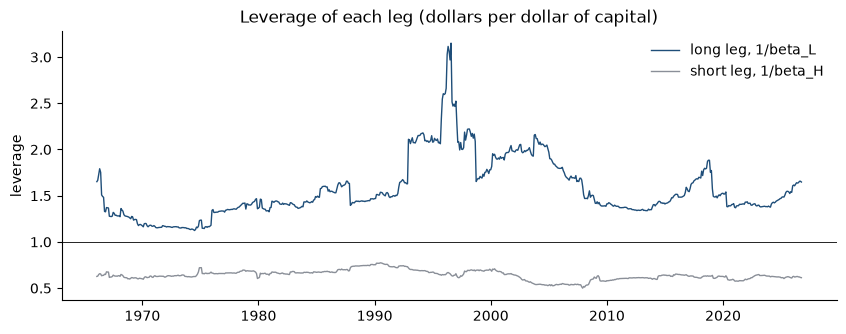

In [8]:
cols = ["beta_L", "beta_H", "lev_L", "lev_H", "cash", "n_L", "n_H"]
summary = book[cols].agg(["median", "min", "max"]).T
summary["min_date"] = [book[c].idxmin().strftime("%Y-%m") for c in cols]
summary["max_date"] = [book[c].idxmax().strftime("%Y-%m") for c in cols]
show(summary, precision=2)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(book.index, book["lev_L"], color="#1f4e79", lw=1, label="long leg, 1/beta_L")
ax.plot(book.index, book["lev_H"], color="#8a8f98", lw=1, label="short leg, 1/beta_H")
ax.axhline(1, color="black", lw=0.6)
ax.set(title="Leverage of each leg (dollars per dollar of capital)", ylabel="leverage")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

### 3.2 Performance

The book's return is a self-financing excess return. Each leg is shown **unlevered**, as its own excess return held long. Drawdowns are measured on the compounded path of each excess return. 1966-01 to 2026-09.

In [9]:
perf = pd.DataFrame({"book": bc.performance(book["book"], mkt),
                     "long leg (low beta), unlevered": bc.performance(book["r_L"], mkt),
                     "short leg (high beta), unlevered": bc.performance(book["r_H"], mkt)}).T
show(perf, pct=["mean", "vol", "worst_month", "max_dd", "alpha"], precision=2)

,mean,vol,sharpe,sharpe_se,skew,worst_month,max_dd,dd_peak,dd_trough,alpha,t_alpha,beta,months
book,8.75%,10.87%,0.81,0.13,-0.50,-18.09%,-54.85%,2007-05,2009-10,7.37%,5.47,0.20,729
"long leg (low beta), unlevered",9.13%,14.79%,0.62,0.13,-0.44,-21.98%,-57.14%,2007-05,2009-02,3.73%,3.37,0.77,729
"short leg (high beta), unlevered",9.31%,28.14%,0.33,0.13,0.29,-32.61%,-83.51%,1968-12,1974-12,-1.15%,-0.57,1.49,729


### 3.3 Ex-ante against realized beta

In [10]:
m = mkt.reindex(book.index)
real_L, real_H = bc.ols(book["r_L"], m)[1], bc.ols(book["r_H"], m)[1]
beta_check = pd.DataFrame({
    "ex-ante beta (avg)": [book["beta_L"].mean(), book["beta_H"].mean()],
    "realized beta": [real_L, real_H],
    "leverage (avg)": [book["lev_L"].mean(), book["lev_H"].mean()],
}, index=["long leg", "short leg"])
beta_check["levered realized beta"] = beta_check["realized beta"] * beta_check["leverage (avg)"]
show(beta_check)
approx = beta_check["levered realized beta"].iloc[0] - beta_check["levered realized beta"].iloc[1]
print(f"book: ex-ante beta 0, avg-leverage approximation {approx:.2f}, "
      f"regression beta {bc.ols(book['book'], m)[1]:.2f} (2014-01 on: {bc.ols(book['book'].loc['2014':], m.loc['2014':])[1]:.2f})")

,ex-ante beta (avg),realized beta,leverage (avg),levered realized beta
long leg,0.663,0.769,1.563,1.202
short leg,1.570,1.489,0.641,0.955


book: ex-ante beta 0, avg-leverage approximation 0.25, regression beta 0.20 (2014-01 on: 0.30)


The long leg's average ex-ante beta is 0.66, but its realized beta is 0.77; the short leg's is 1.57 against a realized 1.49. Even after shrinkage toward one, the estimates overstate the spread. As a result the long leg is over-levered (1.56 × 0.77 ≈ 1.20 of market exposure) and the short leg under-levered (0.64 × 1.49 ≈ 0.95). The difference, about 0.25, is the book's leftover beta; the regression gives 0.20, because leverage varies over time rather than sitting at its average. So the book is not market-neutral after the fact: it carries a positive beta (0.30 since 2014), which is why its alpha (7.4%) is below its mean excess return (8.8%).

### 3.4 Turnover and capacity

One-way turnover is $\sum_i |w_{i,t} - w^{\text{drift}}_{i,t-1}|$ on signed, levered weights, unhalved. The average starts with the second formation month. Composition is the share of each leg's levered weight in stocks below the NYSE 20th percentile of market cap and in stocks priced under $5, measured at formation.

In [11]:
comp_cols = ["turnover", "small_L", "small_H", "penny_L", "penny_H"]
capacity = pd.DataFrame({"1966-01 to 2026-09": book[comp_cols].mean(),
                         "2014-01 to 2026-09": book.loc["2014":, comp_cols].mean()}).T
capacity.columns = ["one-way turnover / month", "long: below NYSE p20", "short: below NYSE p20",
                    "long: price < $5", "short: price < $5"]
show(capacity, pct=capacity.columns)

,one-way turnover / month,long: below NYSE p20,short: below NYSE p20,long: price < $5,short: price < $5
1966-01 to 2026-09,35.05%,59.11%,56.10%,21.23%,28.90%
2014-01 to 2026-09,34.41%,53.70%,47.07%,20.45%,29.13%


The book trades about 35% of capital a month (34% since 2014), or roughly four times its capital a year. More than half of each leg sits in stocks below the NYSE 20th percentile (59% long and 56% short over the full sample; 54% and 47% since 2014). A fifth of the long leg and nearly 30% of the short leg are in stocks priced under $5. Rank weights ignore size, so a micro-cap carries as much weight as a mega-cap with the same beta rank. Capacity would bind first in the short leg, where thousands of small, low-priced, high-beta names have to be borrowed and shorted, and borrow availability, fees and price impact limit the size. The long leg's micro-cap share limits it next. Section 6 prices this turnover, and a value-weighted or size-screened book (a Section 4 candidate) would show how much of the premium survives in large stocks.

### For Sections 4–6: how to reuse the book

```python
book, weights = bc.build_book(sort_beta, panel, lev_beta=None, weighting="rank", screen=None, return_weights=True)
```
- `sort_beta`: the beta frame that ranks stocks and splits the legs. `lev_beta`: the beta whose leg-weighted average sets leverage (defaults to `sort_beta`). For the volatility-against-correlation option, sort on the component and pass `lev_beta=combined`.
- `weighting`: `"rank"`, `"value"` or `"equal"`. `screen`: a boolean month × permno frame; `False` removes a stock at that formation date.
- `book` columns: `beta_L, beta_H, lev_L, lev_H, cash, n_L, n_H, r_L, r_H` (unlevered leg excess returns), `book` (excess return), `rf`, `turnover`, the composition shares, and `failed`.
- `weights`: signed levered weights by formation date and permno, for the Section 6 cost calculation.